<center><h1>Park_Peter_HW6</h1></center>

Name: Peter Park
<br>
Github Username: pspark1052
<br>
USC ID: 4240400712

## 1. Tree-Based Methods

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, roc_auc_score, RocCurveDisplay
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from imblearn.ensemble import BalancedRandomForestClassifier
plt.rcParams['figure.figsize'] = (4.5, 3.5)

### (a) Download the APS Failure data

In [2]:
train = pd.read_csv('data/aps_failure_training_set.csv', skiprows=20, na_values='na')
test = pd.read_csv('data/aps_failure_test_set.csv', skiprows=20, na_values='na')

### (b) Data Preparation

#### (i) Research what types of techniques are usually used

usual ways to handle missing values are dropping the rows that have them, filling them in with the mean, median, or mode, filling them in from the nearest neighbors (KNN), or predicting them from the other features with regression.

I used median imputation since features are really skewed and the median isn't thrown off by outliers. I fillled the training set with training medians and the test set with test medians.

In [3]:
X_train = train.drop(columns='class')
X_train = X_train.fillna(X_train.median())
y_train = (train['class'] == 'pos').astype(int)
X_test = test.drop(columns='class')
X_test = X_test.fillna(X_test.median())
y_test = (test['class'] == 'pos').astype(int)

#### (ii) Calculate the coefficient of variation

In [4]:
cv = (X_train.std() / X_train.mean()).sort_values(ascending=False)
cv

cf_000    244.887517
co_000    244.507385
ad_000    244.322816
cs_009    237.930554
dh_000    123.216097
             ...    
bo_000      0.792383
bp_000      0.753392
bq_000      0.718534
br_000      0.689112
cd_000      0.000000
Length: 170, dtype: float64

#### (iii) Plot a correlation matrix

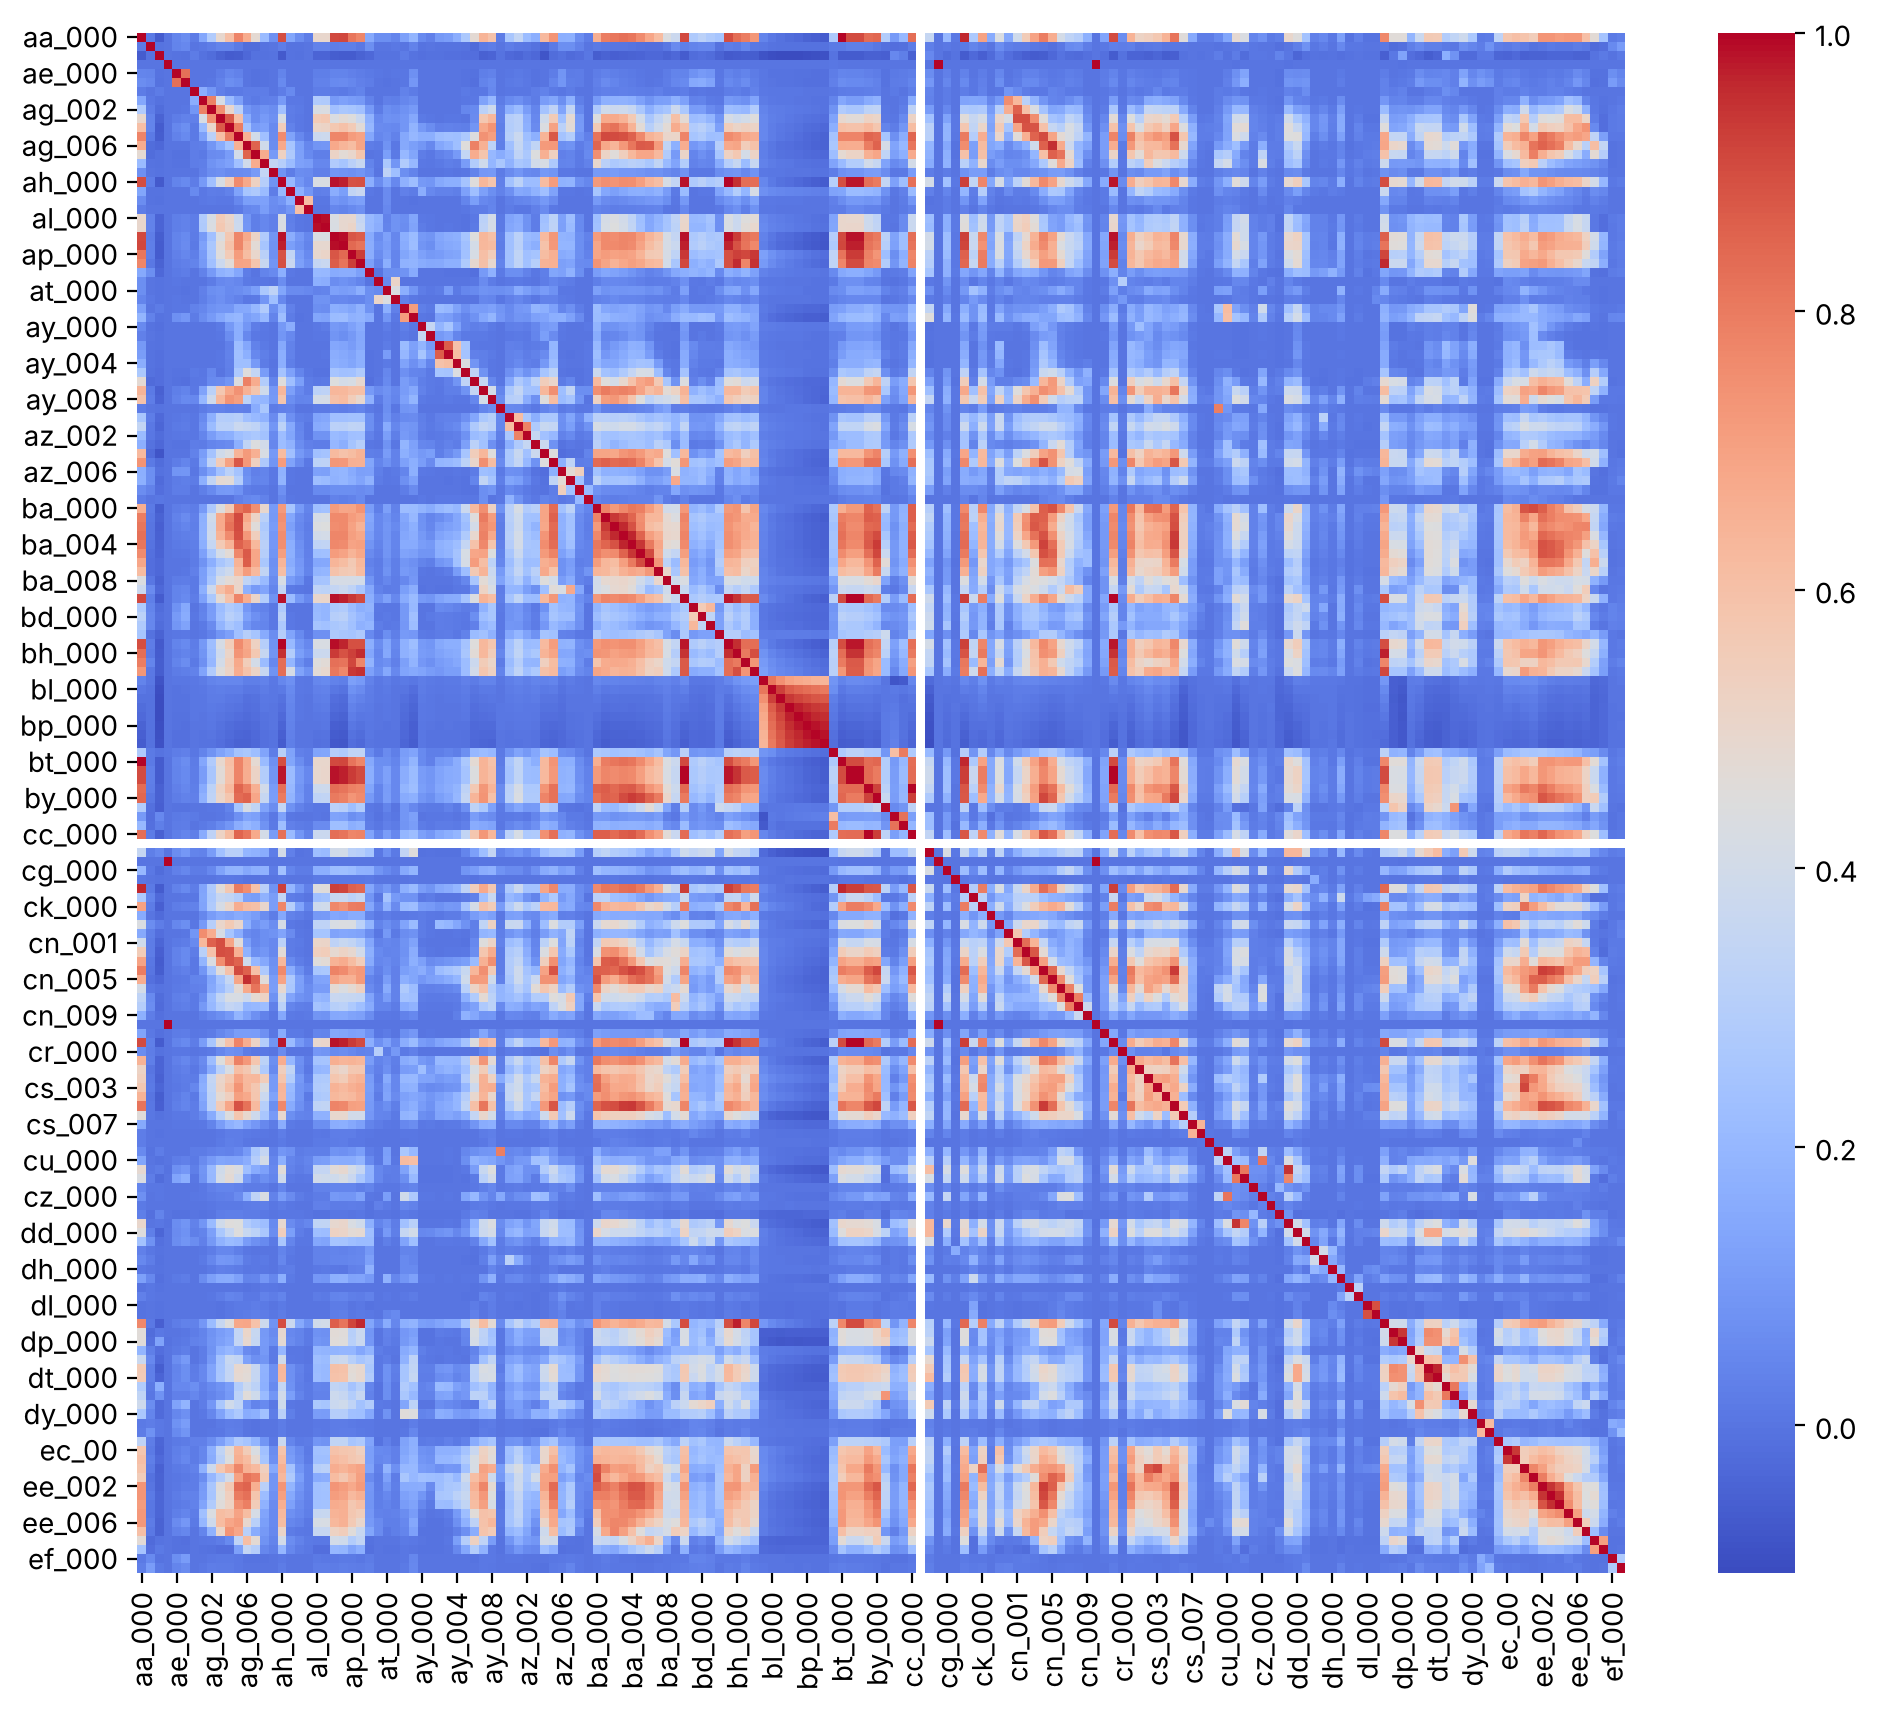

In [5]:
plt.figure(figsize=(12, 10))
sns.heatmap(X_train.corr(), cmap='coolwarm')
plt.show()

#### (iv) Make scatter plots and box plots

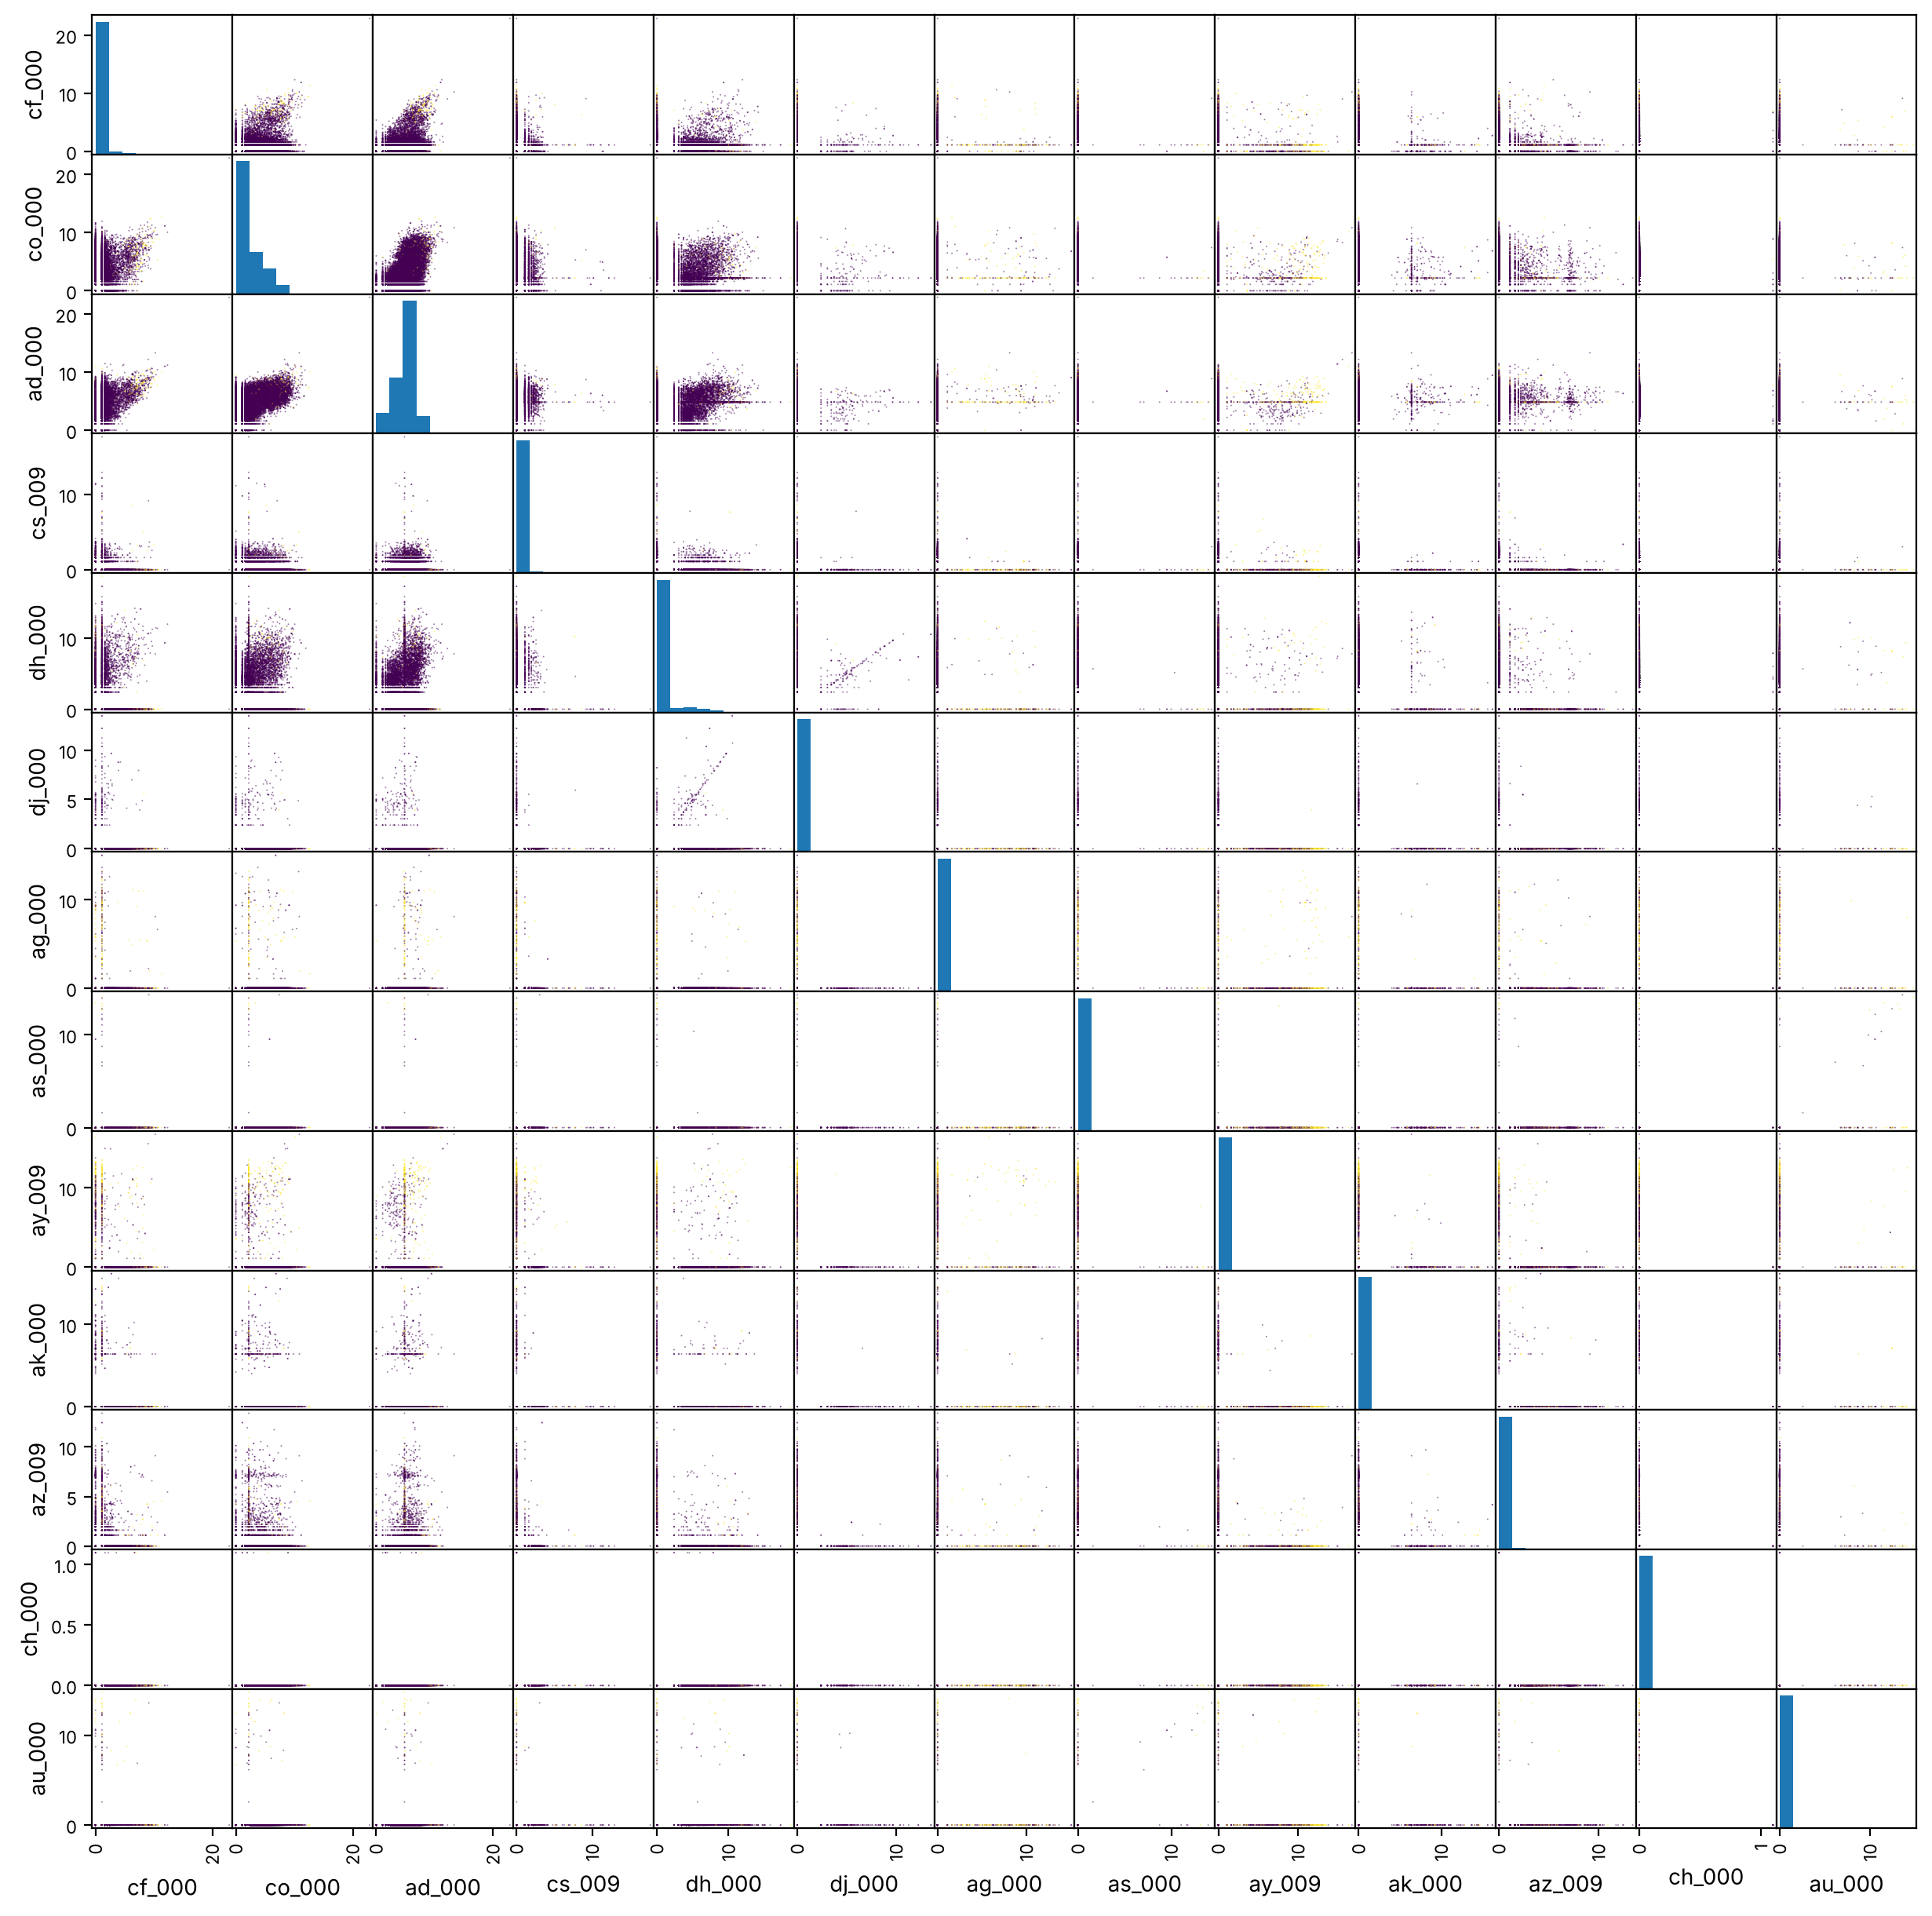

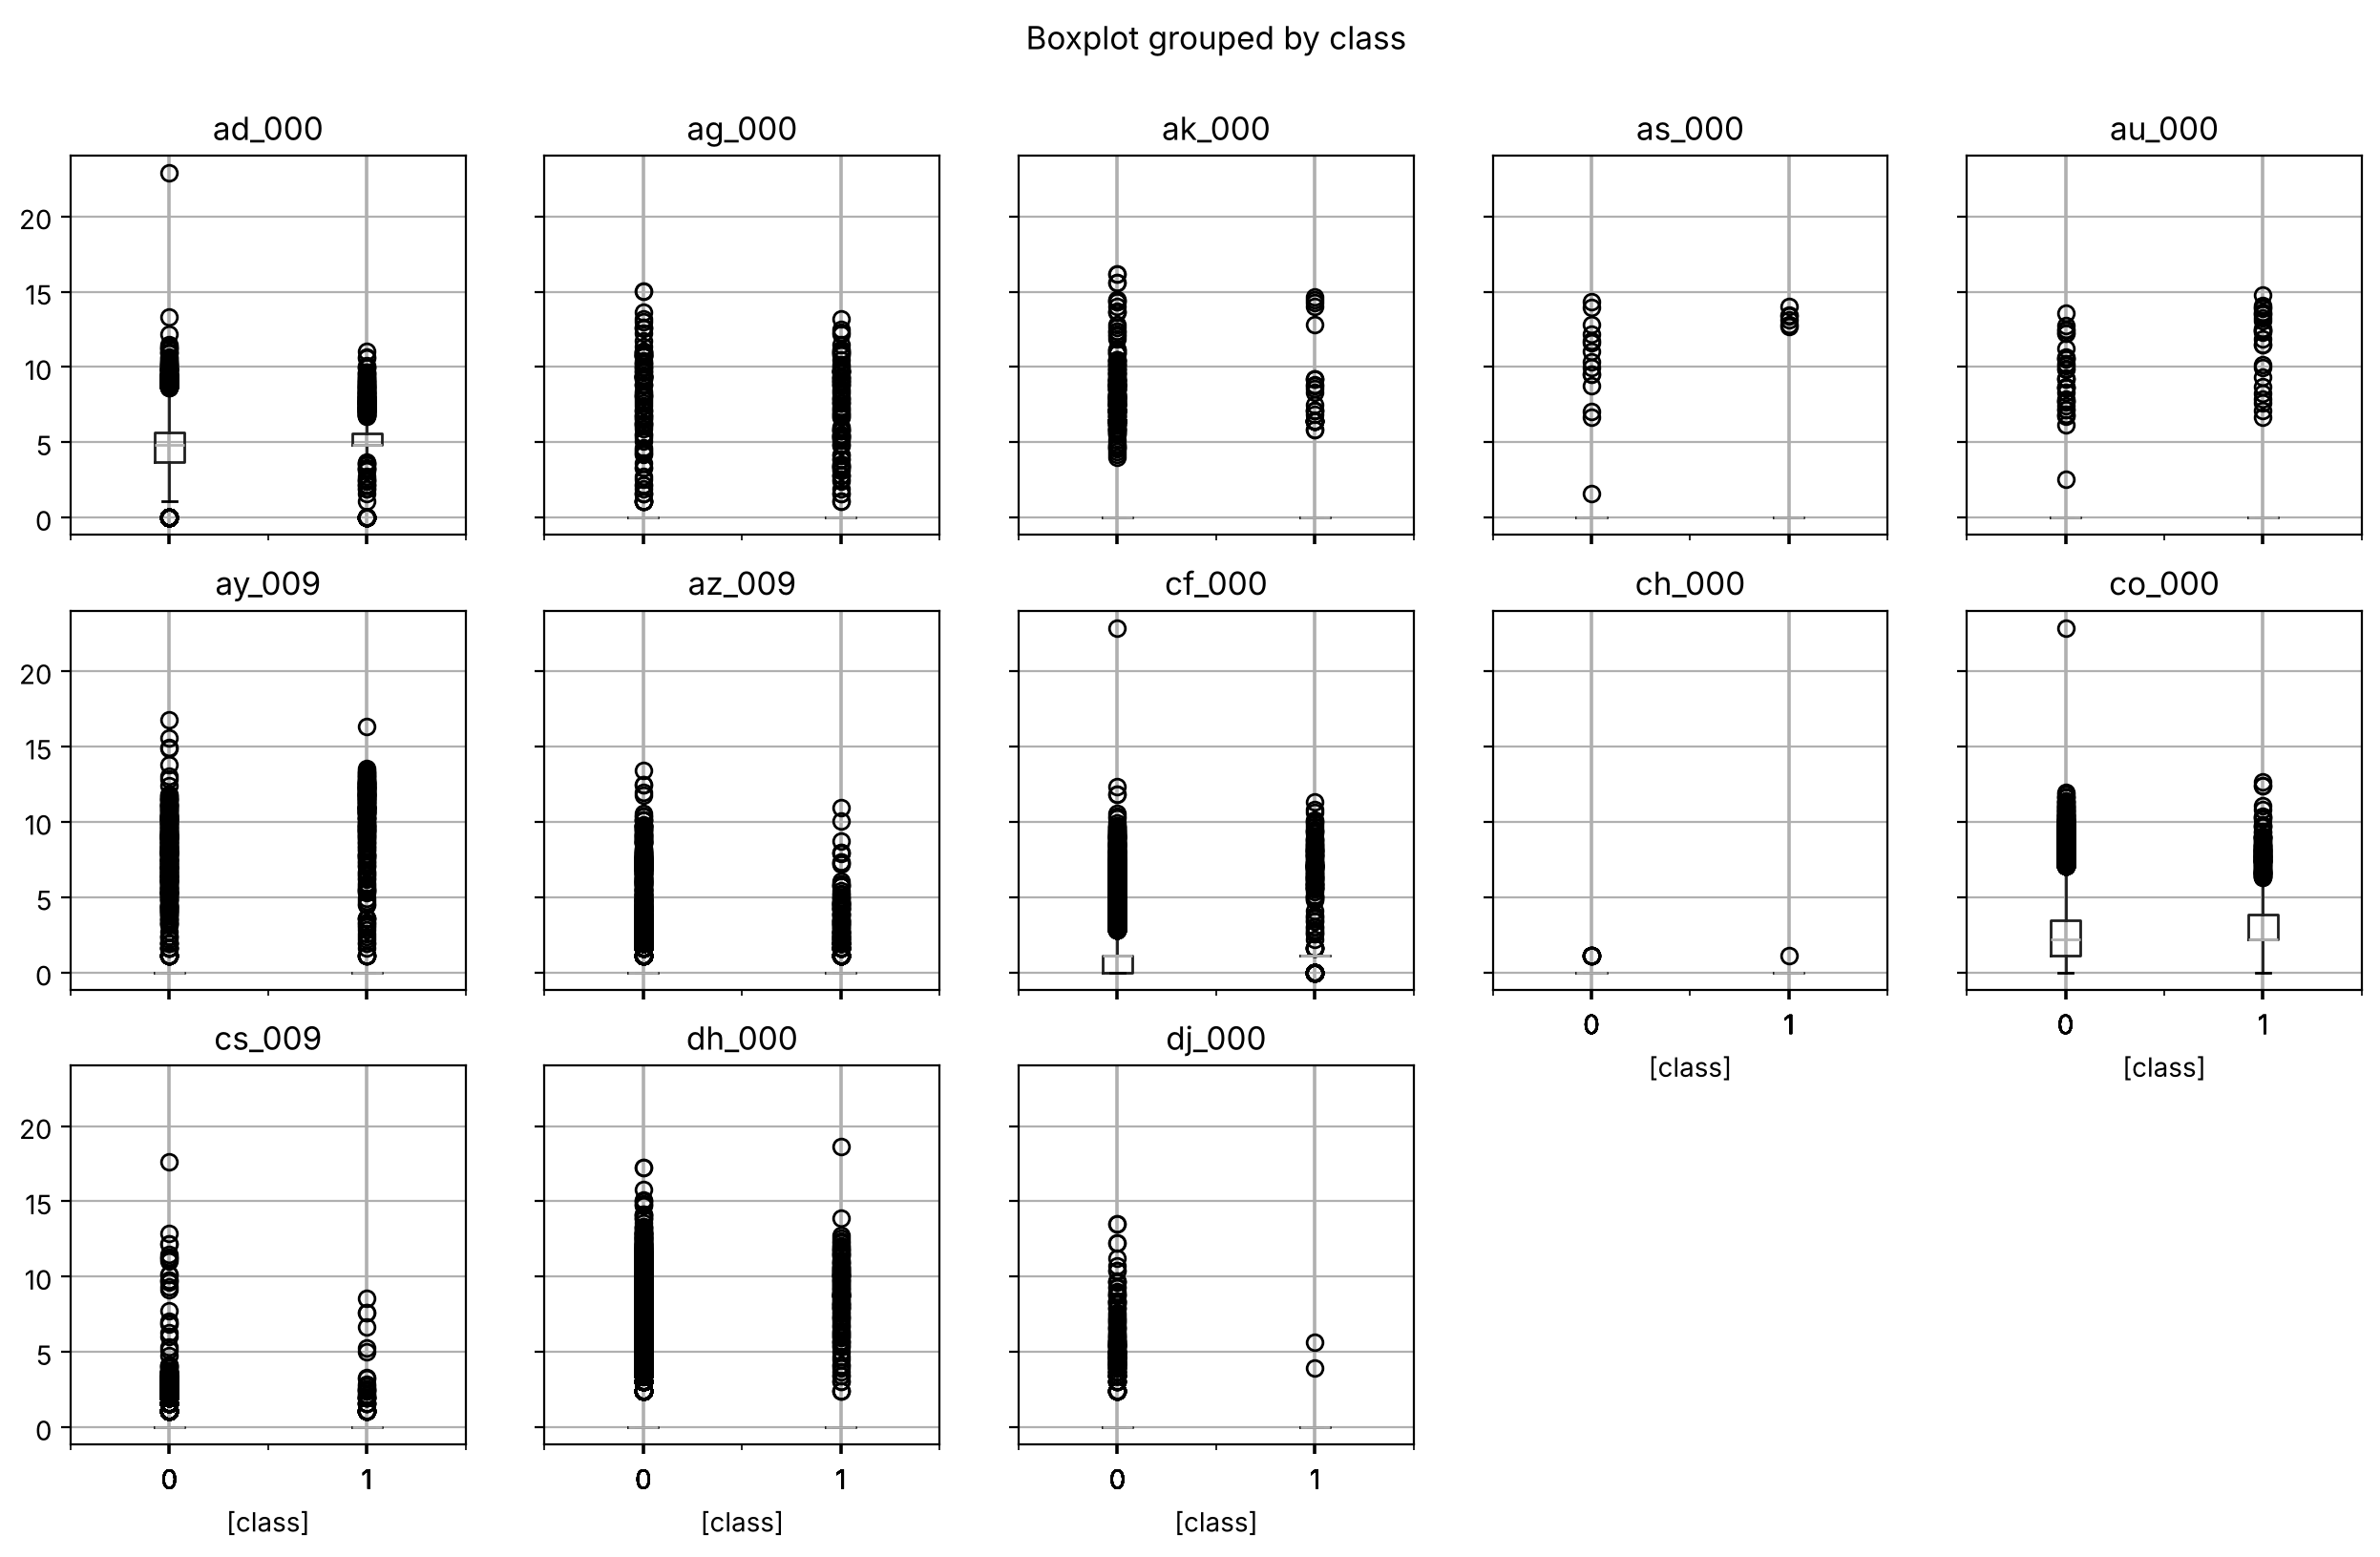

In [6]:
top = cv.index[:int(np.sqrt(170))]
L = np.log1p(X_train[top])
pd.plotting.scatter_matrix(L, c=y_train, figsize=(15, 15), s=2)
plt.show()
L['class'] = y_train
L.boxplot(by='class', layout=(3, 5), figsize=(15, 9))
plt.show()

I plotted log(1 + x) since the features are really skewed. No we cant tell if a feature is significant just from scatter plots. Some features, like co_000 and au_000, run a bit higher for the positive class, but the two classes overlap a lot.

#### (v) Is this data set imbalanced?

In [7]:
y_train.value_counts()

class
0    59000
1     1000
Name: count, dtype: int64

There are 59000 negatives and 1,000 positives, so yes, its very imbalanced.

### (c) Train a random forest

In [8]:
def report(model):
    for name, X, y in [('Train', X_train, y_train), ('Test', X_test, y_test)]:
        pred = model.predict(X)
        print(name)
        print(pd.DataFrame(confusion_matrix(y, pred), index=['True neg', 'True pos'], columns=['Pred neg', 'Pred pos']))
        print('Misclassification:', round((pred != y).mean(), 4), ' AUC:', round(roc_auc_score(y, model.predict_proba(X)[:, 1]), 4))
    ax = plt.gca()
    RocCurveDisplay.from_estimator(model, X_train, y_train, name='Train', ax=ax)
    RocCurveDisplay.from_estimator(model, X_test, y_test, name='Test', ax=ax)
    plt.show()

Train
          Pred neg  Pred pos
True neg     59000         0
True pos         0      1000


Misclassification: 0.0  AUC: 1.0
Test
          Pred neg  Pred pos
True neg     15610        15
True pos       103       272


Misclassification: 0.0074  AUC: 0.9944


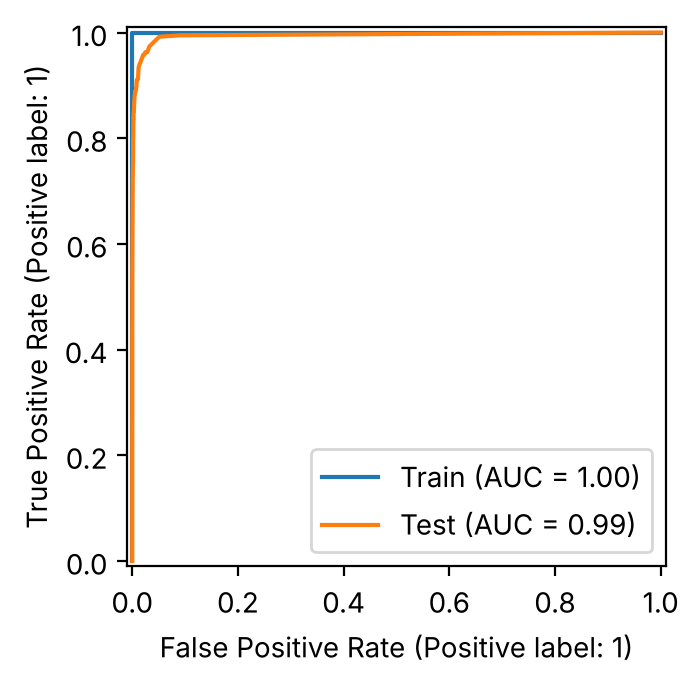

OOB error: 0.0062


In [9]:
rf = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=0, n_jobs=-1)
rf.fit(X_train, y_train)
report(rf)
print('OOB error:', round(1 - rf.oob_score_, 4))

The OOB error (0.0062) is close to the test error (0.0074), so OOB is a good estimate of the test error.

### (d) Research class imbalance in random forest

Common fixes are class weights, undersampling the majority class in each bootstrap sample (balanced random forest), and oversampling the minority class. I used balanced random forest, where each tree is trained on all the positives and an equal-sized random sample of negatives, so every tree sees balanced classes.

/usr/local/lib/python3.13/site-packages/imblearn/ensemble/_forest.py:827: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


Train
          Pred neg  Pred pos
True neg     55809      3191
True pos         0      1000


Misclassification: 0.0532  AUC: 0.9972
Test
          Pred neg  Pred pos
True neg     14820       805
True pos         6       369
Misclassification: 0.0507  AUC: 0.9917


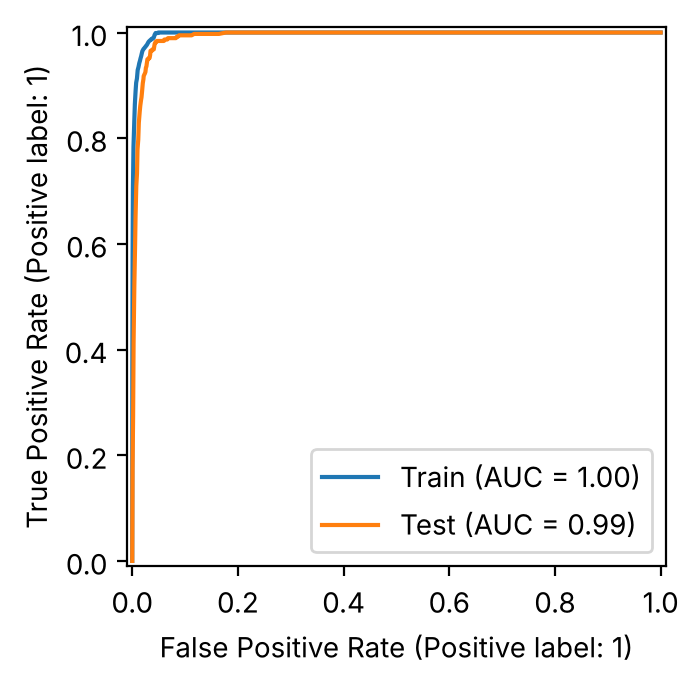

OOB error: 0.0334


In [10]:
brf = BalancedRandomForestClassifier(n_estimators=100, oob_score=True, bootstrap=True, replacement=False, random_state=0, n_jobs=-1)
brf.fit(X_train, y_train)
report(brf)
print('OOB error:', round(1 - brf.oob_score_, 4))

Compared to (c), the balanced forest misses way fewer positives on the test set (6 vs 103) but has a lot more false positives (805 vs 15), so its missclassification is higher (0.0507 vs 0.0074). Test AUC is about the same. The OOB error (0.0334) is a bit lower than the test error (0.0507).

### (e) XGBoost and Model Trees

Train
          Pred neg  Pred pos
True neg     59000         0
True pos         1       999
Misclassification: 0.0  AUC: 1.0
Test
          Pred neg  Pred pos
True neg     15605        20
True pos        83       292
Misclassification: 0.0064  AUC: 0.994


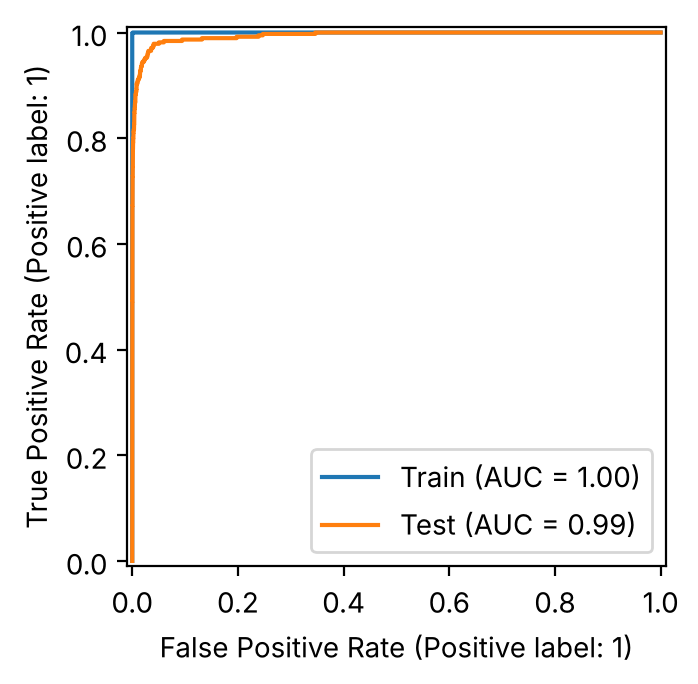

Best alpha: {'reg_alpha': 0.1}  5-fold CV error: 0.0059


In [11]:
alphas = [0, 0.01, 0.1, 1, 10, 100]
xgb = GridSearchCV(XGBClassifier(random_state=0), {'reg_alpha': alphas}, cv=5)
xgb.fit(X_train, y_train)
report(xgb)
print('Best alpha:', xgb.best_params_, ' 5-fold CV error:', round(1 - xgb.best_score_, 4))

The 5-fold CV error (0.0059) is close to the test error (0.0064).

### (f) Use SMOTE to pre-process your data

Train
          Pred neg  Pred pos
True neg     59000         0
True pos         1       999
Misclassification: 0.0  AUC: 1.0
Test
          Pred neg  Pred pos
True neg     15516       109
True pos        52       323


Misclassification: 0.0101  AUC: 0.9917


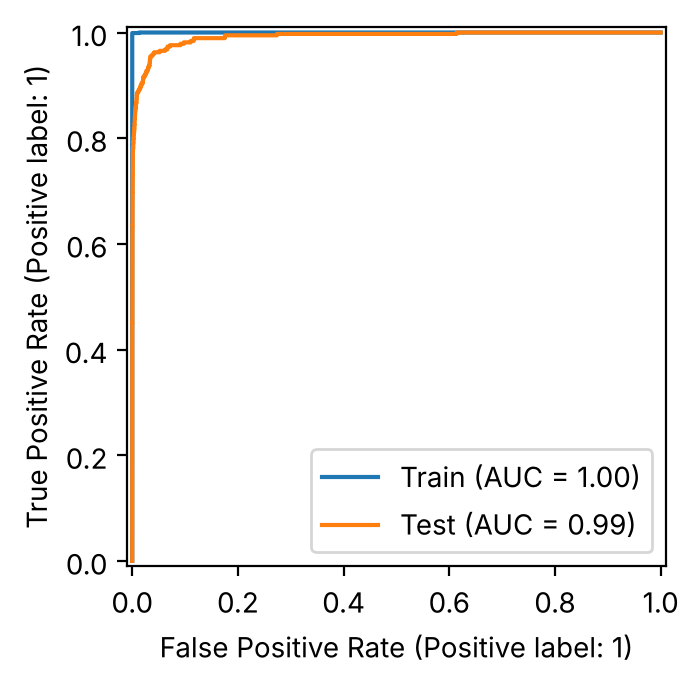

Best alpha: {'xgb__reg_alpha': 0}  5-fold CV error: 0.0064


In [12]:
smote = GridSearchCV(Pipeline([('smote', SMOTE(random_state=0)), ('xgb', XGBClassifier(random_state=0))]),
                     {'xgb__reg_alpha': alphas}, cv=5)
smote.fit(X_train, y_train)
report(smote)
print('Best alpha:', smote.best_params_, ' 5-fold CV error:', round(1 - smote.best_score_, 4))

right way is to apply SMOTE only to the training folds inside CV (thats what the Pipeline does), not to the whole training set before CV. Otherwise synthetic points made from the validation rows leak into training.

The 5-fold CV error (0.0064) is lower than the test error (0.0101). Compared to section e, SMOTE misses fewer positives on the test set (52 vs 83) but has more false positives (109 vs 20), so its test error is higher (0.0101 vs 0.0064). Test AUC is about the same.

## 2. ISLR 6.6.3

(a) iv. Steadily decreases. As s goes up, the model gets more flexible and fits the training data better.

(b) ii. Decreases at first, then goes back up in a U shape. More flexibility helps at first, then the model starts to overfit.

(c) iii. Steadily increases, since a more flexible model has more variance.

(d) iv. Steadily decreases, since a more flexible model has less bias.

(e) v. Stays constant. Irreducible error doesn't depend on the model.

## 3. ISLR 6.6.5

(a) Minimize $(y_1 - \beta_1 x_{11} - \beta_2 x_{12})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{22})^2 + \lambda(\beta_1^2 + \beta_2^2)$

(b) Since $x_{i1} = x_{i2} = x_i$, the RSS term is $\sum_i (y_i - (\beta_1+\beta_2)x_i)^2$. Setting the derivatives to 0:

$-2\sum_i x_i(y_i - (\beta_1+\beta_2)x_i) + 2\lambda\beta_1 = 0$ and $-2\sum_i x_i(y_i - (\beta_1+\beta_2)x_i) + 2\lambda\beta_2 = 0$

Subtracting gives $\lambda(\beta_1 - \beta_2) = 0$, so $\hat\beta_1 = \hat\beta_2$.

(c) Minimize $(y_1 - \beta_1 x_{11} - \beta_2 x_{12})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{22})^2 + \lambda(|\beta_1| + |\beta_2|)$

(d) The RSS only depends on $\beta_1 + \beta_2$, and $|\beta_1| + |\beta_2| = |\beta_1 + \beta_2|$ as long as $\beta_1$ and $\beta_2$ have the same sign. So once the best sum $\beta_1 + \beta_2 = s$ is found, any pair with that sum and the same sign gives the same objective value. That means the lasso solution isn't unique. It's a whole line segment.

## 4. ISLR 8.4.5

Majority vote: 6 of the 10 probabilities are above 0.5, so it's Red.

Average probability: 4.5 / 10 = 0.45, which is below 0.5, so it's Green.

## 5. ISLR 9.7.3

(a)

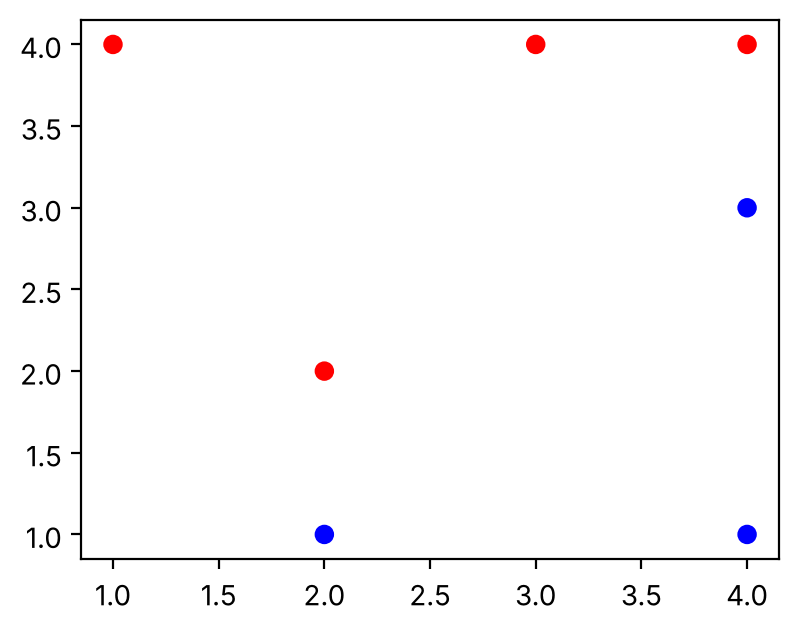

In [13]:
x1 = [3, 2, 4, 1, 2, 4, 4]
x2 = [4, 2, 4, 4, 1, 3, 1]
colors = ['red', 'red', 'red', 'red', 'blue', 'blue', 'blue']
plt.scatter(x1, x2, c=colors)
plt.show()

(b) The hyper plane goes through (2, 1.5) and (4, 3.5), so it's $0.5 - X_1 + X_2 = 0$. This plot also shows the margins for d (dashed) and the support vectors for e (circled).

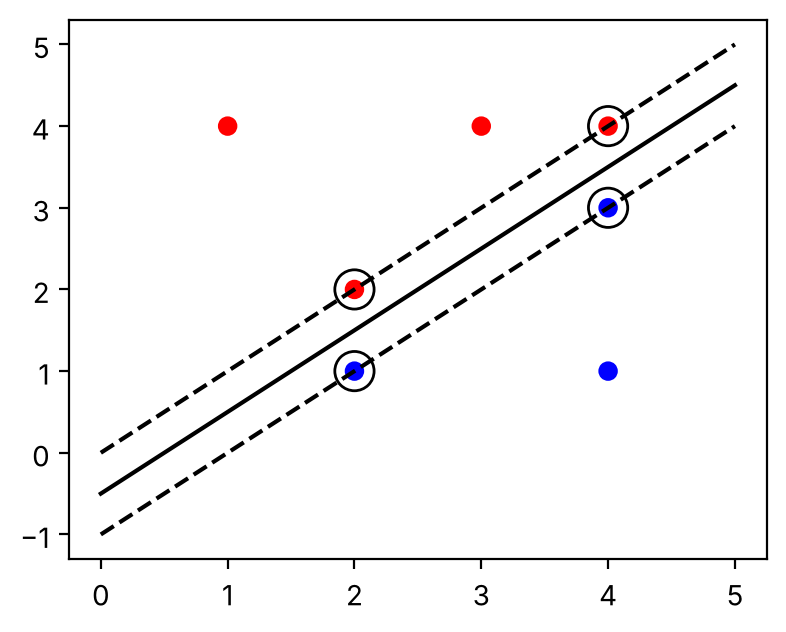

In [14]:
xs = np.linspace(0, 5, 100)
plt.scatter(x1, x2, c=colors)
plt.plot(xs, xs - 0.5, 'k')
plt.plot(xs, xs, 'k--')
plt.plot(xs, xs - 1, 'k--')
plt.scatter([2, 4, 2, 4], [2, 4, 1, 3], s=200, facecolors='none', edgecolors='k')
plt.show()

(c) Classify to red if $0.5 - X_1 + X_2 > 0$, and to Blue otherwise. $\beta_0 = 0.5$, $\beta_1 = -1$, $\beta_2 = 1$.

(d) The margin is $0.5/\sqrt{2} \approx 0.354$. The margin lines are $X_2 = X_1$ and $X_2 = X_1 - 1$ (dashed in the plot in b).

(e) The support vectors are (2,2), (4,4), (2,1), and (4,3) (circled in the plot in (b)).

(f) (4,1) isnt a support vector, so moving it a little wouldn't change the maximal margin hyperplane.

(g) $0.1 - X_1 + X_2 = 0$

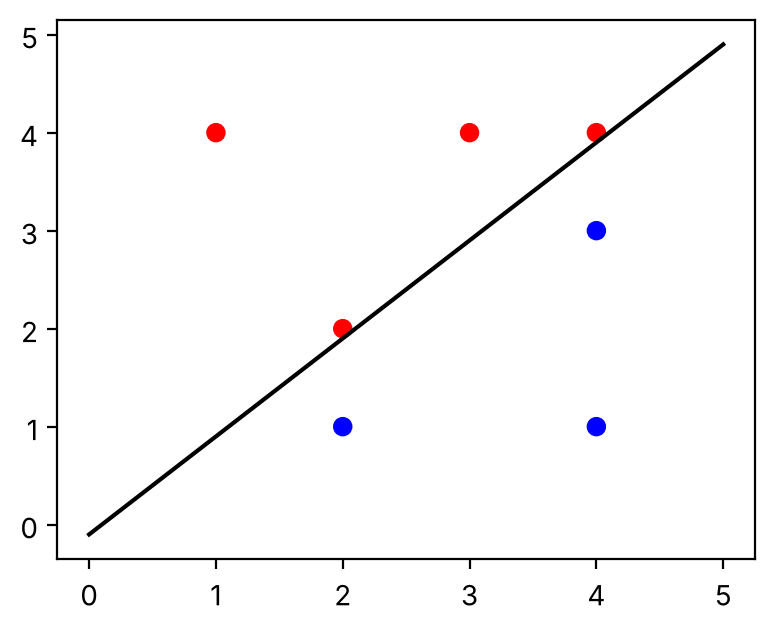

In [15]:
plt.scatter(x1, x2, c=colors)
plt.plot(xs, xs - 0.1, 'k')
plt.show()

(h) Adding a Red point at (4,2) makes the classes not separable anymore.

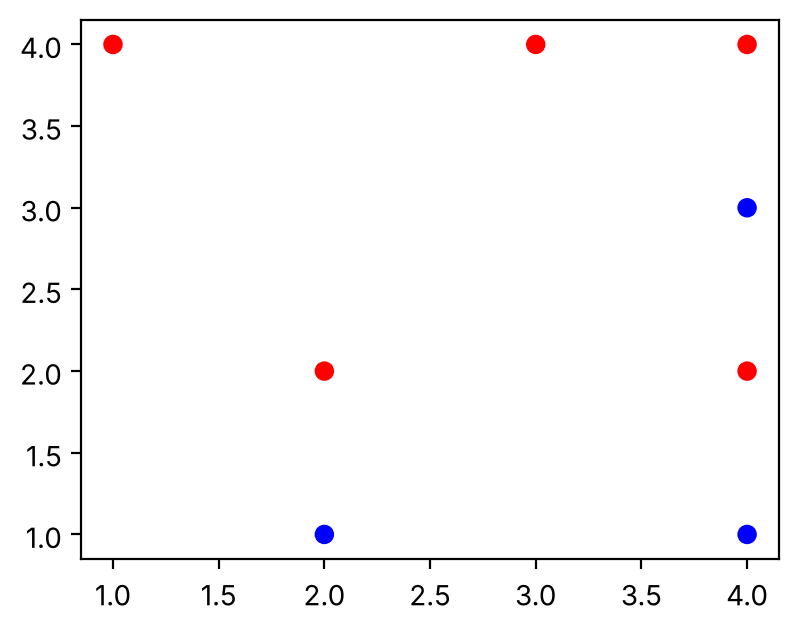

In [16]:
plt.scatter(x1 + [4], x2 + [2], c=colors + ['red'])
plt.show()